# Depending parameters

In the following we show how to link parameters in the same model or
among different models, and how to make a paramter depending on other
parameters according to a mathematical expression.


## Example: linked paramters for EBL

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import jetset
print('tested with',jetset.__version__)

tested with 1.4.0rc3


In [3]:
from jetset.jet_model import Jet
from jetset.template_2Dmodel import EBLAbsorptionTemplate
from jetset.model_manager import FitModel

my_jet = Jet(electron_distribution='lppl', name='jet_flaring')
my_jet.parameters.z_cosm.val = 0.01

ebl_franceschini = EBLAbsorptionTemplate.from_name('Franceschini_2008')

composite_model = FitModel(nu_size=500, name='EBL corrected')
composite_model.add_component(my_jet)
composite_model.add_component(ebl_franceschini)

composite_model.show_pars()

composite_model.link_par(par_name='z_cosm', from_model='Franceschini_2008', to_model='jet_flaring')
v=0.03001
my_jet.parameters.z_cosm.val = v
assert (composite_model.Franceschini_2008.parameters.z_cosm.val==v)
assert (composite_model.Franceschini_2008.parameters.z_cosm.linked==True)

composite_model.composite_expr = '%s*%s'%(my_jet.name,ebl_franceschini.name)
composite_model.eval()

#if plot is True:
#    composite_model.plot_model()

composite_model.save_model('ebl_jet.pkl')
new_composite_model=FitModel.load_model('ebl_jet.pkl')
new_composite_model.show_pars()
v=2.0
new_composite_model.jet_flaring.parameters.z_cosm.val=v
print('new_composite_model.Franceschini_2008.parameters.z_cosm.val',new_composite_model.Franceschini_2008.parameters.z_cosm.val,'v',v)
assert (new_composite_model.Franceschini_2008.parameters.z_cosm.val == v)
assert (new_composite_model.Franceschini_2008.parameters.z_cosm.linked == True)

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_flaring,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_flaring,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_flaring,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_flaring,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_flaring,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_flaring,z_cosm,redshift,,1.000000e-02,0.000000e+00,--,False,False
jet_flaring,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_flaring,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_flaring,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_flaring,gamma0_log_parab,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_flaring,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_flaring,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_flaring,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_flaring,gamma0_log_parab,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False
jet_flaring,s,LE_spectral_slope,,2.000000e+00,-1.000000e+01,1.000000e+01,False,False
jet_flaring,r,spectral_curvature,,4.000000e-01,-1.500000e+01,1.500000e+01,False,False
jet_flaring,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_flaring,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_flaring,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_flaring,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


new_composite_model.Franceschini_2008.parameters.z_cosm.val 2.0 v 2.0


## Example: depending pars for bkn power-law emitters

here we create a custom `bkn` distribution where we impose a functional dependence among the low and high-energy spectral index.

In [4]:
from jetset.jet_emitters import EmittersDistribution
import numpy as np



from jetset.jet_model import Jet

j = Jet(emitters_distribution='bkn')


j.parameters


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


None

the functional dependence can be provided by a python function, where the argument (`p` in this case) is the same name as the parameter:

In [5]:
def f_p(p):
    return p+1
j.make_dependent_par(par='p_1',depends_on=['p'],par_expr=f_p)
j.parameters.p.val=2
np.testing.assert_allclose(j.parameters.p_1.val, j.parameters.p.val + 1)
j.parameters

adding par: p to  p_1
==> par p_1 is depending on ['p'] according to expr:   p_1 =
def f_p(p):
    return p+1



model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


None

as you can notice, now a message is shown describing the dependence of the parameters 

It is also possible to set the dependence function as a string that can be evaluated

In [6]:
j.make_dependent_par(par='p_1',depends_on=['p'],par_expr='p+1')
j.parameters.p.val=2
np.testing.assert_allclose(j.parameters.p_1.val, j.parameters.p.val + 1)
j.parameters

==> par p_1 is depending on ['p'] according to expr:   p_1 =
p+1


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


None

In principle, you can use strings for short expressions, and functions for more complicated formulas.

You can print the actual expression/function for the depending parameter using the `print_par_expr` method:

In [7]:
j.parameters.p_1.par_expression_source_code

==> par p_1 is depending on ['p'] according to expr:   p_1 =
p+1


In [8]:
j.save_model('jet.pkl')
new_jet=Jet.load_model('jet.pkl')


In [9]:
new_jet.parameters.p.val=2.5
np.testing.assert_allclose(new_jet.parameters.p_1.val, new_jet.parameters.p.val + 1)
new_jet.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_break,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,p(M),LE_spectral_slope,,2.500000e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,"*p_1(D,p)",HE_spectral_slope,,3.500000e+00,-1.000000e+01,1.000000e+01,False,True
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None

## Example depending par: R depends on variability time scale


In [10]:
jet=Jet(emitters_distribution='plc')

jet.add_user_par('t_var_day',val=1, units='d',val_min=0.001,val_max=30)


def par_func(t_var_day,beam_obj,z_cosm):
    from astropy.constants import c
    R=t_var_day*86400*beam_obj/(1+z_cosm)*c.cgs.value
    return R

jet.make_dependent_par(par='R', depends_on=['t_var_day', 'beam_obj', 'z_cosm',], par_expr=par_func)


adding par: t_var_day to  R
adding par: beam_obj to  R
adding par: z_cosm to  R
==> par R is depending on ['t_var_day', 'beam_obj', 'z_cosm'] according to expr:   R =
def par_func(t_var_day,beam_obj,z_cosm):
    from astropy.constants import c
    R=t_var_day*86400*beam_obj/(1+z_cosm)*c.cgs.value
    return R



In [11]:
jet.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,z_cosm)",region_size,cm,2.354733e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj(M),beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm(M),redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_cut,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


None

If you are using a jet model with BulkFactor and viewing angle

In [12]:
jet=Jet(emitters_distribution='plc',beaming_expr='bulk_theta')

jet.add_user_par('t_var_day',val=1, units='d',val_min=0.001,val_max=30)


def par_func(t_var_day,BulkFactor,z_cosm,theta):
    from astropy.constants import c
    beta=np.sqrt(1-(1/(BulkFactor*BulkFactor)))
    beaming_factor=1/(BulkFactor*(1-beta*np.cos(np.radians(theta))))
    R=t_var_day*86400*beaming_factor/(1+z_cosm)*c.cgs.value
    return R

jet.make_dependent_par(par='R', depends_on=['t_var_day', 'BulkFactor', 'z_cosm','theta'], par_expr=par_func)

adding par: t_var_day to  R
adding par: BulkFactor to  R
adding par: z_cosm to  R
adding par: theta to  R
==> par R is depending on ['t_var_day', 'BulkFactor', 'z_cosm', 'theta'] according to expr:   R =
def par_func(t_var_day,BulkFactor,z_cosm,theta):
    from astropy.constants import c
    beta=np.sqrt(1-(1/(BulkFactor*BulkFactor)))
    beaming_factor=1/(BulkFactor*(1-beta*np.cos(np.radians(theta))))
    R=t_var_day*86400*beaming_factor/(1+z_cosm)*c.cgs.value
    return R



In [13]:
jet.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,"*R(D,theta)",region_size,cm,4.696244e+16,1.000000e+03,1.000000e+30,False,True
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta(M),jet-viewing-angle,deg,1.000000e-01,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor(M),jet-bulk-factor,lorentz-factor*,1.000000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm(M),redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False


None

## Example depending par: Building a Jet model with B function of R_H and R_0

In this example we create a fuctional dependence among the paramters `B`, `R_H` introducing user custom pararameters. Wewant that  the value of the mangentic field in the jet is a function or `R_H`, and  of the initial value of `B=B0` at `R=R_H0`, according to the expression: 

$B=B_0(R_0/R_H)^{1.1}$

In [14]:
jet=Jet(emitters_distribution='plc')
fit_model_lsb=FitModel( jet=jet, name='SSC-best-fit-lsb',template=None)
fit_model_lsb.jet_leptonic.parameters.beam_obj.fit_range = [5, 50]
fit_model_lsb.jet_leptonic.parameters.R_H.val=5E17
fit_model_lsb.jet_leptonic.parameters.R_H.frozen=False
fit_model_lsb.jet_leptonic.parameters.R_H.fit_range = [1E15, 1E19]
fit_model_lsb.jet_leptonic.parameters.R.fit_range = [10 ** 15.5, 10 ** 17.5]

fit_model_lsb.jet_leptonic.add_user_par(name='B0',units='G',val=1E3,val_min=0,val_max=None)
fit_model_lsb.jet_leptonic.add_user_par(name='R0', units='cm', val=5E13, val_min=0, val_max=None)
fit_model_lsb.jet_leptonic.add_user_par(name='m_B', val=1, val_min=1, val_max=2)
fit_model_lsb.jet_leptonic.parameters.R0.frozen=True
fit_model_lsb.jet_leptonic.parameters.B0.frozen=True

def par_func(R0,B0,R_H,m_B): 
    return B0*np.power((R0/R_H),m_B)

fit_model_lsb.jet_leptonic.make_dependent_par(par='B', depends_on=['B0', 'R0', 'R_H','m_B'], par_expr=par_func)

B0=fit_model_lsb.jet_leptonic.parameters.B0.val
R0 = fit_model_lsb.jet_leptonic.parameters.R0.val
R_H = fit_model_lsb.jet_leptonic.parameters.R_H.val
m_B= fit_model_lsb.jet_leptonic.parameters.m_B.val

np.testing.assert_allclose(fit_model_lsb.jet_leptonic.parameters.B.val, par_func(R0,B0,R_H,m_B))

adding par: B0 to  B
adding par: R0 to  B
adding par: R_H to  B
adding par: m_B to  B
==> par B is depending on ['B0', 'R0', 'R_H', 'm_B'] according to expr:   B =
def par_func(R0,B0,R_H,m_B): 
    return B0*np.power((R0/R_H),m_B)



In [15]:

fit_model_lsb.jet_leptonic.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H(M),region_position,cm,5.000000e+17,0.000000e+00,--,False,False
jet_leptonic,"*B(D,m_B)",magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,True
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,1.000000e-01,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_cut,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False


None

In [16]:
fit_model_lsb.save_model('test.pkl')

In [17]:
fit_model_lsb=FitModel.load_model('test.pkl')

In [18]:
B0=fit_model_lsb.jet_leptonic.parameters.B0.val
R0 = fit_model_lsb.jet_leptonic.parameters.R0.val
R_H = fit_model_lsb.jet_leptonic.parameters.R_H.val
m_B= fit_model_lsb.jet_leptonic.parameters.m_B.val

np.testing.assert_allclose(fit_model_lsb.jet_leptonic.parameters.B.val, par_func(R0,B0,R_H,m_B))

Text(0, 0.5, 'B (G)')

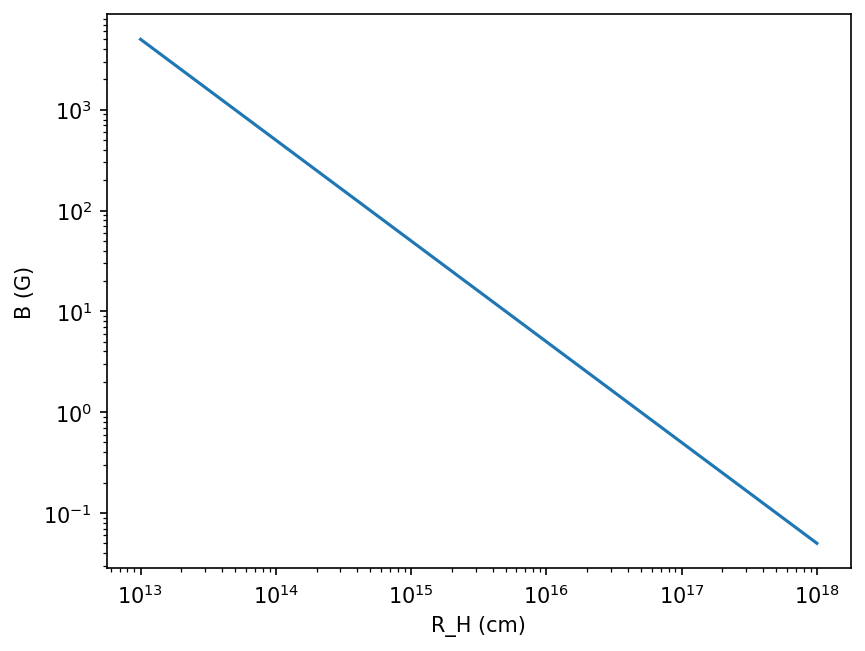

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(dpi=150)
R_H_array=np.logspace(13,18,100)
B_array=np.zeros(R_H_array.shape)
for ID,R_H in enumerate(R_H_array):
    fit_model_lsb.jet_leptonic.parameters.R_H.val=R_H
    B_array[ID]=fit_model_lsb.jet_leptonic.parameters.B.val

plt.loglog(R_H_array,B_array)
plt.xlabel('R_H (cm)')
plt.ylabel('B (G)')

## Removing the dependenencies

for the entire ``fit_model``

In [20]:
fit_model_lsb.parameters.reset_dependencies()

or, for a specific component

In [21]:
fit_model_lsb.jet_leptonic.parameters.reset_dependencies()

In [22]:
fit_model_lsb.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.000000e+00,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.000000e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.000000e+02,0.000000e+00,--,False,False
jet_leptonic,gamma_cut,turn-over-energy,lorentz-factor*,1.000000e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,p,LE_spectral_slope,,2.000000e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,R,region_size,cm,5.000000e+15,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+18,0.000000e+00,--,False,False
jet_leptonic,B,magnetic_field,gauss,5.000000e-02,0.000000e+00,--,False,True
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,1.000000e+01,1.000000e-04,--,False,False


None

Text(0, 0.5, 'B (G)')

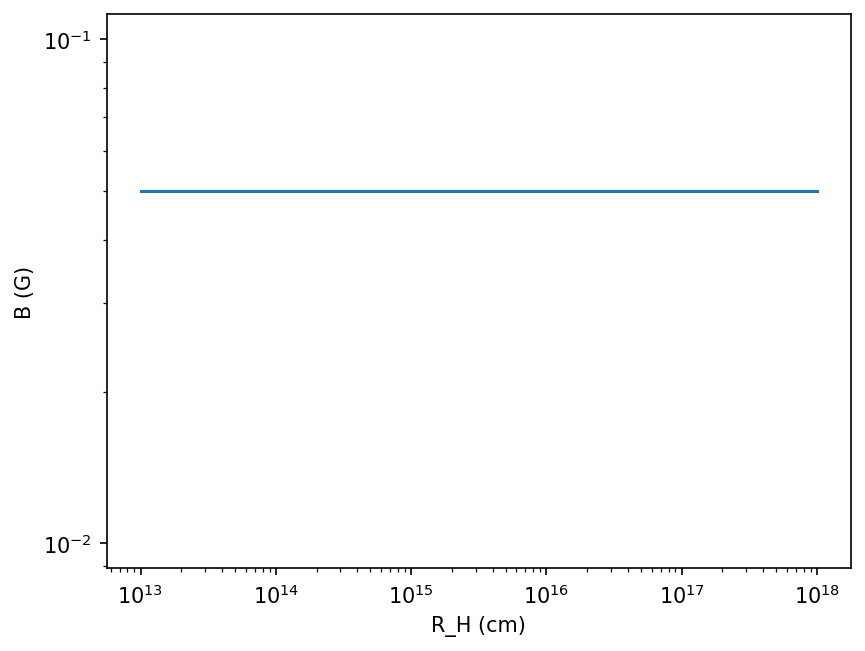

In [23]:
%matplotlib inline

plt.figure(dpi=150)
R_H_array=np.logspace(13,18,100)
B_array=np.zeros(R_H_array.shape)
for ID,R_H in enumerate(R_H_array):
    fit_model_lsb.jet_leptonic.parameters.R_H.val=R_H
    B_array[ID]=fit_model_lsb.jet_leptonic.parameters.B.val

plt.loglog(R_H_array,B_array)
plt.xlabel('R_H (cm)')
plt.ylabel('B (G)')

## Example depending par: fitting with a Jet model with depending pars


In this example we show how to use the previous model during a Fit

In [24]:
from jetset.test_data_helper import  test_SEDs
from jetset.data_loader import ObsData,Data
from jetset.plot_sedfit import PlotSED
from jetset.test_data_helper import  test_SEDs

In [25]:
data=Data.from_file(test_SEDs[1])


***  binning data in [2276544600.0,9.69946733e+26] Hz  *** 
---> N bins= 88
---> bin_width= 0.2



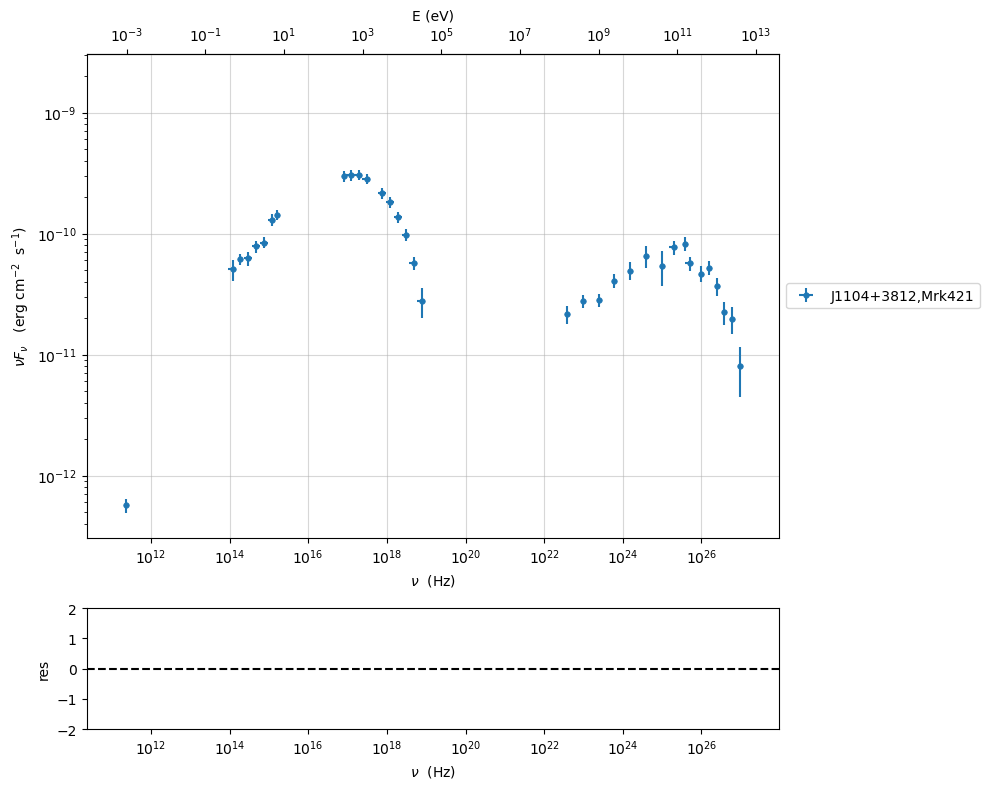

In [26]:
sed_data=ObsData(data_table=data)
sed_data.group_data(bin_width=0.2)

sed_data.add_systematics(0.1,[10.**6,10.**29])
p=sed_data.plot_sed()


*** evaluating spectral indices for data ***



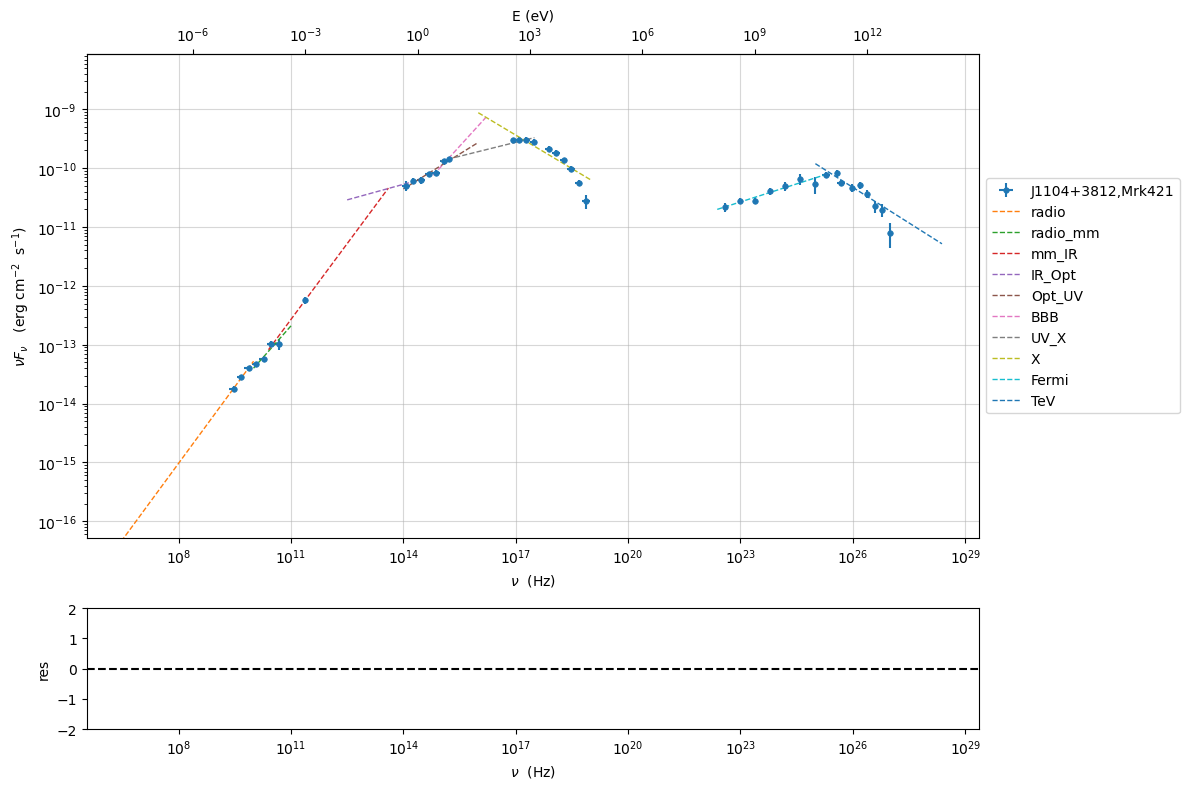

In [27]:
from jetset.sed_shaper import  SEDShape
my_shape=SEDShape(sed_data)
my_shape.eval_indices(minimizer='lsb',silent=True)
p=my_shape.plot_indices()


In [28]:
mm,best_fit=my_shape.sync_fit(check_host_gal_template=False,
                  Ep_start=None,
                  minimizer='lsb',
                  silent=True,
                  fit_range=[10.,21.])


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [10.0, 21.0]
---> class:  HSP





model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.525958e-01,-1.525958e-01,6.482036e-03,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-9.962792e-03,-9.962792e-03,9.541920e-04,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,1.674375e+01,1.674375e+01,2.624853e-02,--,1.669194e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-9.498549e+00,-9.498549e+00,1.847153e-02,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> sync       nu_p=+1.674375e+01 (err=+2.624853e-02)  nuFnu_p=-9.498549e+00 (err=+1.847153e-02) curv.=-1.525958e-01 (err=+6.482036e-03)




*** Log-Polynomial fitting of the IC component ***
---> fit range: [23.0, 29.0]
---> LogCubic fit




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.961746e-01,-1.961746e-01,2.682131e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-4.013229e-02,-4.013229e-02,2.124386e-02,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.521741e+01,2.521741e+01,1.206301e-01,--,2.529193e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.012689e+01,-1.012689e+01,2.978342e-02,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.521741e+01 (err=+1.206301e-01)  nuFnu_p=-1.012689e+01 (err=+2.978342e-02) curv.=-1.961746e-01 (err=+2.682131e-02)



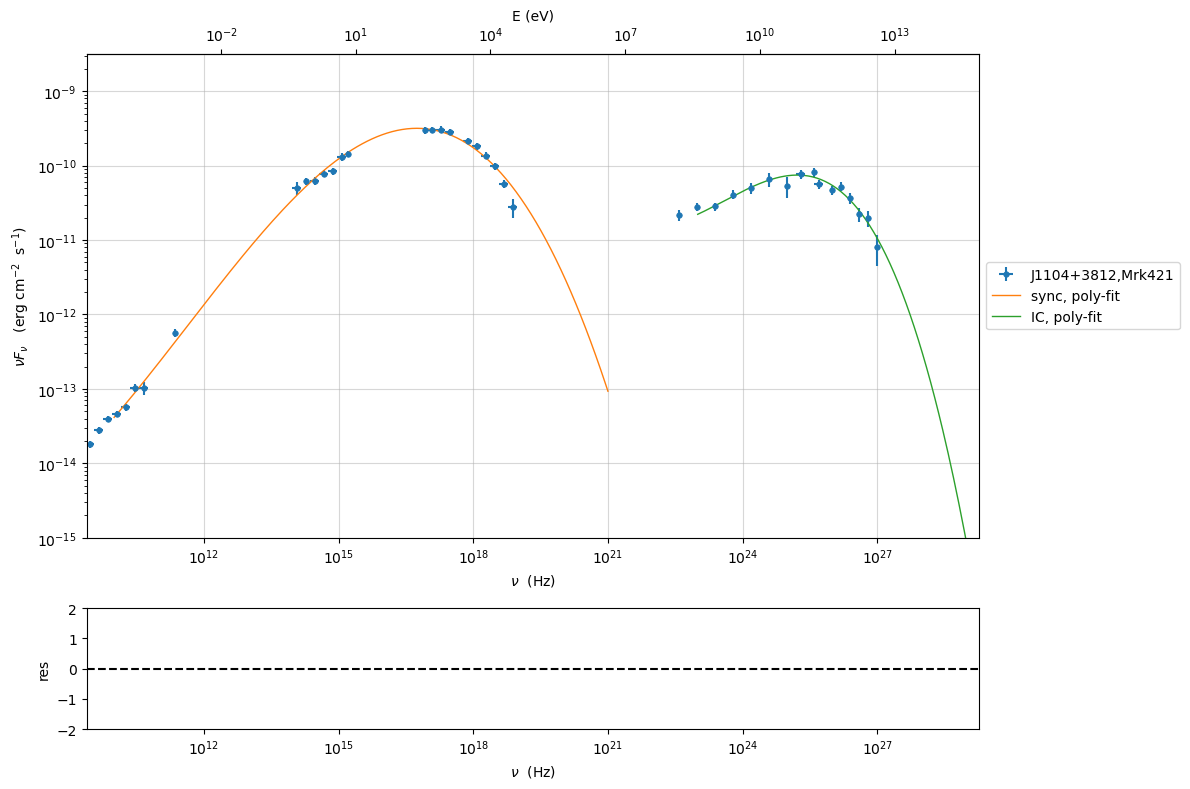

In [29]:
my_shape.IC_fit(fit_range=[23.,29.],minimizer='minuit',silent=True)
p=my_shape.plot_shape_fit()
p.setlim(y_min=1E-15)

In [30]:
from jetset.obs_constrain import ObsConstrain
from jetset.model_manager import  FitModel
sed_obspar=ObsConstrain(beaming=25,
                        B_range=[0.001,0.1],
                        distr_e='lppl',
                        t_var_sec=3*86400,
                        nu_cut_IR=1E12,
                        SEDShape=my_shape)


prefit_jet=sed_obspar.constrain_SSC_model(electron_distribution_log_values=False,silent=True)
prefit_jet.save_model('prefit_jet.pkl')


***  constrains parameters from observable ***



/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/obs_constrain.py:1514: RankWarning: Polyfit may be poorly conditioned
  p=polyfit(nu_p_IC_model_log,B_grid_log,2)


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.050000e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,2.500000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,3.080000e-02,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False


In [31]:
from jetset.minimizer import fit_SED,ModelMinimizer

from jetset.model_manager import  FitModel
from jetset.jet_model import Jet
prefit_jet=Jet.load_model('prefit_jet.pkl')

In [32]:
fit_model=FitModel( jet=prefit_jet, name='SSC-best-fit-lsb',template=None)
fit_model.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,s,LE_spectral_slope,,2.177996e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,r,spectral_curvature,,7.629792e-01,-1.500000e+01,1.500000e+01,False,False
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.050000e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None

In [33]:
fit_model.jet_leptonic.parameters.beam_obj.fit_range = [5, 50]
fit_model.jet_leptonic.parameters.R_H.val=5E17
fit_model.jet_leptonic.parameters.R_H.frozen=False
fit_model.jet_leptonic.parameters.R_H.fit_range = [1E15, 1E19]
fit_model.jet_leptonic.parameters.R.fit_range = [10 ** 15.5, 10 ** 17.5]
fit_model.jet_leptonic.parameters.gamma0_log_parab.fit_range = [1E3,1E6]
fit_model.jet_leptonic.parameters.gmin.fit_range = [10,1000]
fit_model.jet_leptonic.parameters.gmax.fit_range = [1E5,1E8]

fit_model.jet_leptonic.add_user_par(name='B0',units='G',val=1E3,val_min=0,val_max=None)
fit_model.jet_leptonic.add_user_par(name='R0', units='cm', val=5E13, val_min=0, val_max=None)
fit_model.jet_leptonic.add_user_par(name='m_B', val=1, val_min=1, val_max=2)
fit_model.jet_leptonic.parameters.R0.frozen=True
fit_model.jet_leptonic.parameters.B0.frozen=True

def par_func(R0,B0,R_H,m_B): 
    return B0*np.power((R0/R_H),m_B)

fit_model.jet_leptonic.make_dependent_par(par='B', depends_on=['B0', 'R0', 'R_H','m_B'], par_expr=par_func)
fit_model.parameters

adding par: B0 to  B
adding par: R0 to  B
adding par: R_H to  B
adding par: m_B to  B
==> par B is depending on ['B0', 'R0', 'R_H', 'm_B'] according to expr:   B =
def par_func(R0,B0,R_H,m_B): 
    return B0*np.power((R0/R_H),m_B)



model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,s,LE_spectral_slope,,2.177996e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,r,spectral_curvature,,7.629792e-01,-1.500000e+01,1.500000e+01,False,False
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H(M),region_position,cm,5.000000e+17,0.000000e+00,--,False,False
jet_leptonic,"*B(D,m_B)",magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,True
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None

Text(0, 0.5, 'B (G)')

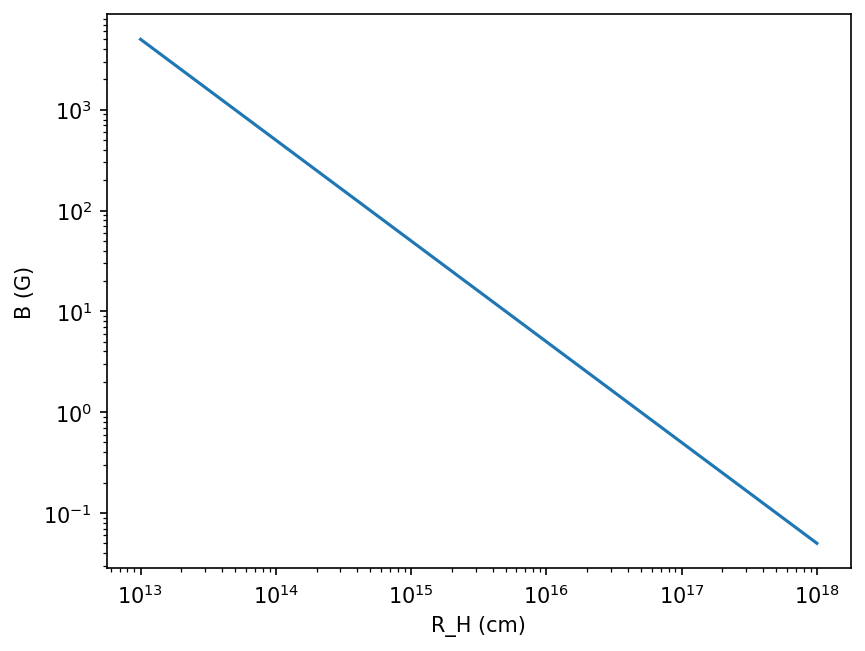

In [34]:
%matplotlib inline

plt.figure(dpi=150)
R_H_array=np.logspace(13,18,100)
B_array=np.zeros(R_H_array.shape)
for ID,R_H in enumerate(R_H_array):
    fit_model.jet_leptonic.parameters.R_H.val=R_H
    B_array[ID]=fit_model.jet_leptonic.parameters.B.val

plt.loglog(R_H_array,B_array)
plt.xlabel('R_H (cm)')
plt.ylabel('B (G)')

In [35]:
fit_model.jet_leptonic.parameters.R_H.val=5E17

In [36]:
fit_model.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,s,LE_spectral_slope,,2.177996e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,r,spectral_curvature,,7.629792e-01,-1.500000e+01,1.500000e+01,False,False
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H(M),region_position,cm,5.000000e+17,0.000000e+00,--,False,False
jet_leptonic,"*B(D,m_B)",magnetic_field,gauss,1.000000e-01,0.000000e+00,--,False,True
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None

As a resuslt of the best fit modeling, we are able to determine the value of `R_H`. We now perform the fit with minuit to get a better estimate of the errors

In [37]:
model_minimizer_minuit=ModelMinimizer('minuit')

In [38]:
model_minimizer_minuit.minimizer.add_simplex=False

In [39]:
best_fit_minuit=model_minimizer_minuit.fit(fit_model,
                                     sed_data,
                                     1E11,
                                     1E29,
                                     fitname='SSC-best-fit-minuit',
                                     repeat=3)

filtering data in fit range = [1.000000e+11,1.000000e+29]
data length 34

*** start fit process ***
----- 
fit run: 0


0it [00:00, ?it/s]

- best chisq=3.20095e+01

fit run: 1
- old chisq=3.20095e+01


0it [00:00, ?it/s]

- best chisq=2.31371e+01

fit run: 2
- old chisq=2.31371e+01


...


converged=True
calls=7503
mesg=


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 19.98                      │             Nfcn = 7503              │
│ EDM = 0.00485 (Goal: 0.0002)     │           time = 11.0 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│         INVALID Minimum          │   ABOVE EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │        Covariance APPROXIMATE        │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ par_0  │  646.798  │   0.028   │            │            │   10    │  1000   │       │
│ 1 │ par_1  │  0.764e6  │  0.016e6  │            │            │ 100000  │  1e+08  │       │
│ 2 │ par_2  │ 537.29e-3 │  0.24e-3  │            │            │    0    │         │       │
│ 3 │ par_3  │  30.13e3  │  0.10e3   │            │            │  1000   │  1e+06  │       │
│ 4 │ par_4  │   2.220   │   0.001   │            │            │   -10   │   10    │       │
│ 5 │ par_5  │ 569.94e-3 │  0.06e-3  │            │            │   -15   │   15    │       │
│ 6 │ par_6  │ 33.78e15  │  0.12e15  │            │            │3.16228e+15│3.16228e+17│       │
│ 7 │ par_7  │ 585.9e15  │  1.8e15   │            │            │  1e+15  │  1e+19  │       │
│ 8 │ par_8  │   32.68   │   0.21    │            │            │    5    │   50    │       │
│ 9 │ par_9  │  0.0494   │  0.0013   │            │            │    0    │         │       │
│ 10│ par_10 │  1.06957  │  0.00004  │            │            │    1    │    2    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘

dof=23
chisq=19.982961, chisq/red=0.868824 null hypothesis sig=0.642939

best fit pars


model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
jet_leptonic,gmin,6.467984e+02,6.467984e+02,2.811687e-02,--,4.697542e+02,1.000000e+01,1.000000e+03,False
jet_leptonic,gmax,7.644545e+05,7.644545e+05,1.585294e+04,--,1.300733e+06,1.000000e+05,1.000000e+08,False
jet_leptonic,N,5.372947e-01,5.372947e-01,2.403922e-04,--,6.642891e-01,0.000000e+00,--,False
jet_leptonic,gamma0_log_parab,3.013388e+04,3.013388e+04,9.856947e+01,--,3.199366e+04,1.000000e+03,1.000000e+06,False
jet_leptonic,s,2.219957e+00,2.219957e+00,9.740003e-04,--,2.177996e+00,-1.000000e+01,1.000000e+01,False
jet_leptonic,r,5.699422e-01,5.699422e-01,5.857420e-05,--,7.629792e-01,-1.500000e+01,1.500000e+01,False
jet_leptonic,R,3.378239e+16,3.378239e+16,1.188304e+14,--,3.403569e+16,3.162278e+15,3.162278e+17,False
jet_leptonic,R_H(M),5.858907e+17,5.858907e+17,1.757898e+15,--,5.000000e+17,1.000000e+15,1.000000e+19,False
jet_leptonic,"*B(D,m_B)",4.447311e-02,--,--,--,1.000000e-01,0.000000e+00,--,True
jet_leptonic,NH_cold_to_rel_e,1.000000e+00,--,--,--,1.000000e+00,0.000000e+00,--,True


-------------------------------------------------------------------------




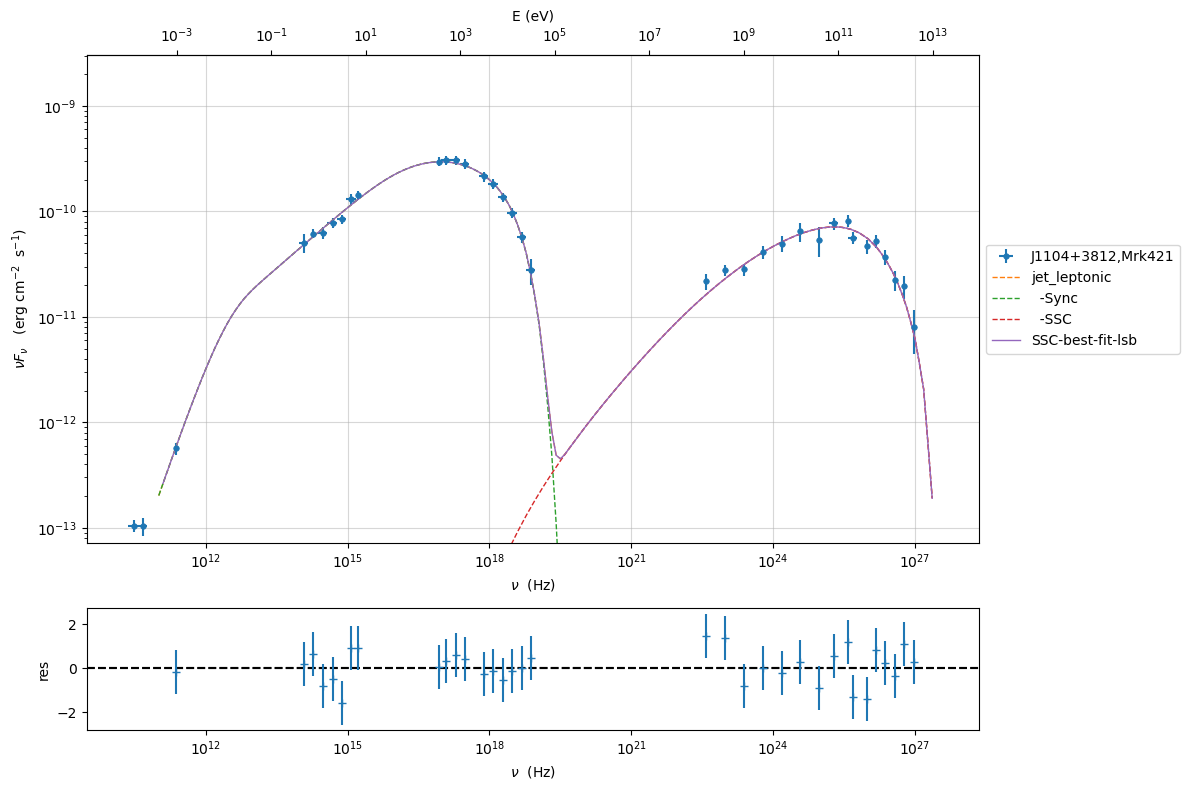

In [40]:
fit_model.plot_model(sed_data=sed_data)

Text(0, 0.5, 'B (G)')

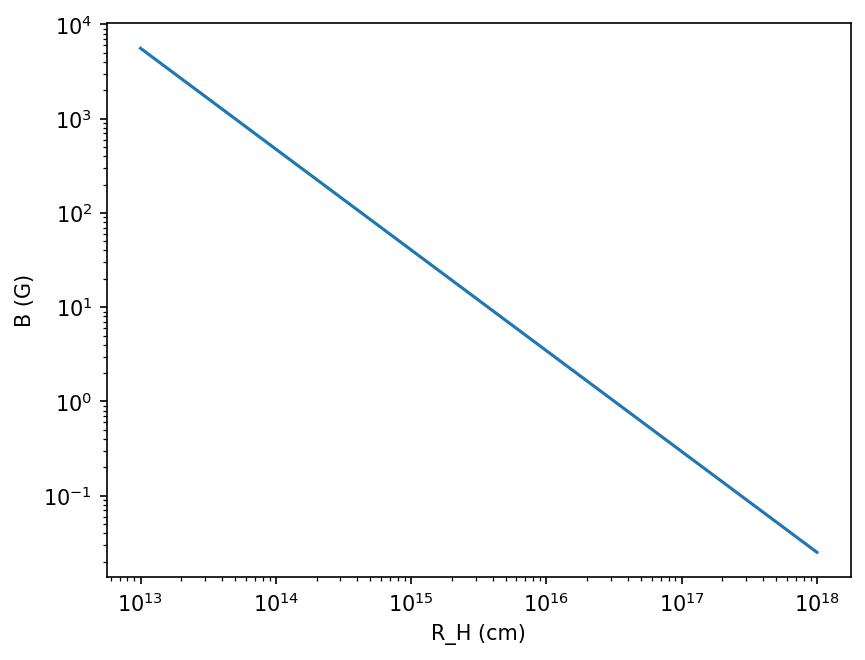

In [41]:
%matplotlib inline
plt.figure(dpi=150)
R_H_array=np.logspace(13,18,100)
B_array=np.zeros(R_H_array.shape)
for ID,R_H in enumerate(R_H_array):
    fit_model.jet_leptonic.parameters.R_H.val=R_H
    B_array[ID]=fit_model.jet_leptonic.parameters.B.val

plt.loglog(R_H_array,B_array)
plt.xlabel('R_H (cm)')
plt.ylabel('B (G)')

In [42]:
fit_model.save_model('test.pkl')


In [43]:
from jetset.model_manager import  FitModel

new_fit_model=FitModel.load_model('test.pkl')

In [44]:
new_fit_model.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,6.467984e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,7.644545e+05,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,5.372947e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.013388e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,s,LE_spectral_slope,,2.219957e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,r,spectral_curvature,,5.699422e-01,-1.500000e+01,1.500000e+01,False,False
jet_leptonic,R,region_size,cm,3.378239e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H(M),region_position,cm,1.000000e+18,0.000000e+00,--,False,False
jet_leptonic,"*B(D,m_B)",magnetic_field,gauss,2.510510e-02,0.000000e+00,--,False,True
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None